In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from curb_core_code import find_minimal_curb_sets

In [3]:
results = []

for game_id in range(10):

    # Generate a new random 4x4 game
    U1 = np.random.uniform(0, 1, (4, 4))
    U2 = np.random.uniform(0, 1, (4, 4))

    # Find all minimal CURB sets
    minimal_sets = find_minimal_curb_sets(U1, U2)

    print(f"Game {game_id + 1}")
    print("Number of minimal CURB sets:", len(minimal_sets))
    print("Minimal CURB sets:", minimal_sets)
    print()

    # Save the result
    results.append(minimal_sets)

Game 1
Number of minimal CURB sets: 2
Minimal CURB sets: [([2], [3]), ([3], [1])]

Game 2
Number of minimal CURB sets: 2
Minimal CURB sets: [([1], [2]), ([0, 3], [0, 1])]

Game 3
Number of minimal CURB sets: 1
Minimal CURB sets: [([1], [0])]

Game 4
Number of minimal CURB sets: 1
Minimal CURB sets: [([1, 2], [0, 1])]

Game 5
Number of minimal CURB sets: 1
Minimal CURB sets: [([2], [3])]

Game 6
Number of minimal CURB sets: 1
Minimal CURB sets: [([0], [1])]

Game 7
Number of minimal CURB sets: 2
Minimal CURB sets: [([1], [0]), ([2], [3])]

Game 8
Number of minimal CURB sets: 1
Minimal CURB sets: [([0, 1, 2, 3], [0, 1, 2, 3])]

Game 9
Number of minimal CURB sets: 1
Minimal CURB sets: [([2], [2])]

Game 10
Number of minimal CURB sets: 2
Minimal CURB sets: [([2], [0]), ([3], [3])]



In [4]:
size_results = []

for game_id, minimal_sets in enumerate(results, start=1):

    for X1, X2 in minimal_sets:

        size_results.append({
            "game_id": game_id,
            "size_p1": len(X1),
            "size_p2": len(X2)
        })

size_df = pd.DataFrame(size_results)

print(size_df)

    game_id  size_p1  size_p2
0         1        1        1
1         1        1        1
2         2        1        1
3         2        2        2
4         3        1        1
5         4        2        2
6         5        1        1
7         6        1        1
8         7        1        1
9         7        1        1
10        8        4        4
11        9        1        1
12       10        1        1
13       10        1        1


In [5]:
size_distribution = (
    size_df
    .groupby(["size_p1", "size_p2"])
    .size()
    .reset_index(name="count")
)

print(size_distribution)

   size_p1  size_p2  count
0        1        1     11
1        2        2      2
2        4        4      1


In [6]:
total_minimal_sets = size_distribution["count"].sum()

size_distribution["frequency"] = (
    size_distribution["count"] / total_minimal_sets
)

size_distribution["percentage"] = (
    size_distribution["frequency"] * 100
)

size_distribution["size"] = (
    size_distribution["size_p1"].astype(str)
    + " x "
    + size_distribution["size_p2"].astype(str)
)

print(size_distribution)

   size_p1  size_p2  count  frequency  percentage   size
0        1        1     11   0.785714   78.571429  1 x 1
1        2        2      2   0.142857   14.285714  2 x 2
2        4        4      1   0.071429    7.142857  4 x 4


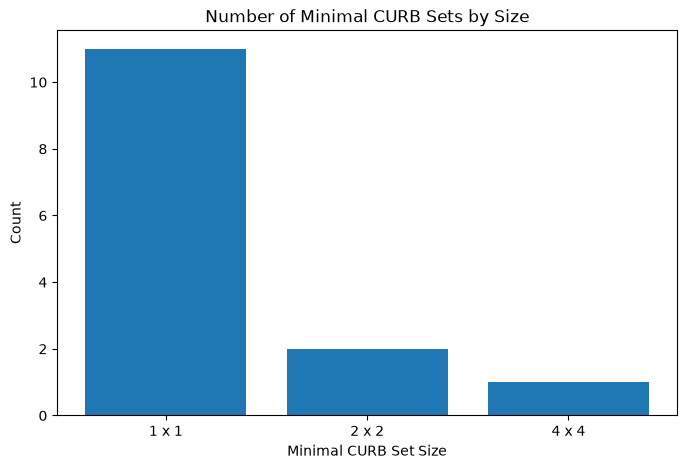

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    size_distribution["size"],
    size_distribution["count"]
)

plt.xlabel("Minimal CURB Set Size")
plt.ylabel("Count")
plt.title("Number of Minimal CURB Sets by Size")

plt.show()

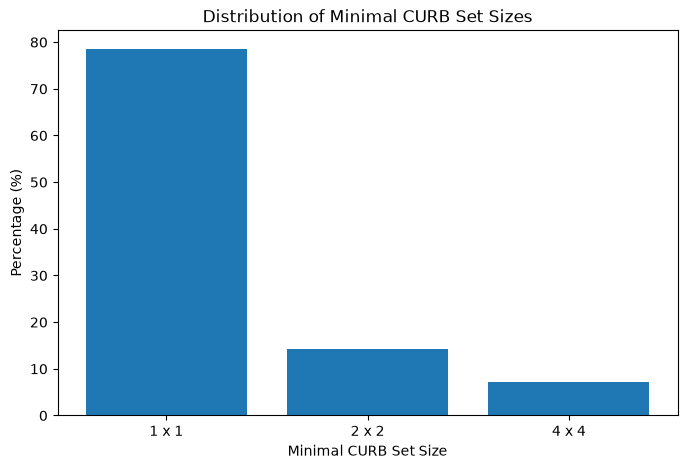

In [8]:
plt.figure(figsize=(8, 5))

plt.bar(
    size_distribution["size"],
    size_distribution["percentage"]
)

plt.xlabel("Minimal CURB Set Size")
plt.ylabel("Percentage (%)")
plt.title("Distribution of Minimal CURB Set Sizes")

plt.show()

In [9]:
size_distribution.to_csv(
    "minimal_curb_size_distribution.csv",
    index=False
)